| Inicio | Anterior | Siguiente |
| --- | --- | --- |
| [🏠](../README.md) | [⏪](../7_METODOS_NUMERICOS_PARA_ODE/7_4_Runge_Kutta.ipynb) | [⏩](../7_METODOS_NUMERICOS_PARA_ODE/7_6_Metodos_implicitos.ipynb) |

# 7.5 Métodos adaptativos: invertir pasos donde hacen falta

Una trayectoria puede tener un transitorio rápido y una fase lenta. Usar el mismo paso en ambos regímenes suele desperdiciar trabajo. Estudiaremos estimación local de error, normas ponderadas, rechazo de pasos, eventos y salida densa. Construiremos un par Euler–Heun sencillo y después compararemos con `solve_ivp`.

Los experimentos son autocontenidos y rápidos en CPU. Requisitos: derivadas, integrales, ecuaciones diferenciales ordinarias y errores numéricos. Ejecuta todas las celdas en orden. La solución exacta se usa como control cuando está disponible; en otros casos se compara contra una solución de referencia más precisa.

## 1. Problema de valor inicial y notación

Un problema de valor inicial tiene forma
$$y'(t)=f(t,y(t)),\qquad y(t_0)=y_0.$$
El estado $y$ puede ser un número o un vector. La función $f$ expresa la ley física y sus unidades son unidades de estado por unidades de tiempo. Bajo continuidad en $t$ y una condición local de Lipschitz en $y$, existe una solución única local; una implementación numérica no reemplaza estos supuestos.

Usaremos una malla $t_n=t_0+nh$ y una aproximación $y_n\approx y(t_n)$. Es esencial distinguir una evaluación de pendiente $f(t_n,y_n)$ de una actualización del estado. Para enfriamiento $y'=-ky$, el coeficiente $k>0$ tiene unidades de inverso del tiempo y la solución exacta es $y_0e^{-kt}$.

Un simulador introduce error de discretización además del error del modelo. Si una red se entrena con sus trayectorias, puede aprender ambas cosas. Por ello se estudian refinamiento, estabilidad y coste antes de usar los resultados como datos científicos.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.optimize import minimize_scalar
plt.rcParams.update({"figure.figsize":(9,4), "axes.grid":True, "font.size":11})
np.set_printoptions(precision=6,suppress=True)

## 2. Dos aproximaciones y un estimador de error

Calculamos en el mismo paso un predictor Euler $y_E=y_n+hk_1$ y un corrector Heun $y_H=y_n+h(k_1+k_2)/2$. Su diferencia
$$e=y_H-y_E=\frac h2(k_2-k_1)$$
es $O(h^2)$ y estima principalmente el error local de la fórmula de orden uno, no directamente todo el error global de Heun. Aceptaremos el estado de Heun pero controlaremos este indicador conservador.

En pares modernos embebidos, dos fórmulas de órdenes cercanos comparten estadios y su diferencia ofrece una estimación sin dos integraciones completas. La relación entre orden del estimador y exponente del controlador debe respetarse.

## 3. Tolerancias por escala y norma ponderada

Para cada componente usamos
$$s_i=\mathrm{atol}_i+\mathrm{rtol}\max(|y_{n,i}|,|y_{H,i}|).$$
La norma RMS es $E=\sqrt{\frac1d\sum_i(e_i/s_i)^2}$. Aceptamos si $E\le1$. `atol` protege cerca de cero y `rtol` define precisión relativa lejos de cero. Para variables con unidades o tamaños muy distintos, tolerancias absolutas por componente resultan más apropiadas.

Esta norma controla un indicador local, no una garantía rígida sobre el error acumulado. Escalas mal elegidas pueden hacer que una componente pequeña pero físicamente importante reciba poco peso.

In [2]:
def adaptive_heun(fun,tspan,y0,rtol=1e-4,atol=1e-7,h0=0.05):
    t0,tf=tspan; t=float(t0); y=np.atleast_1d(np.array(y0,dtype=float))
    times=[t]; states=[y.copy()]; h=h0; rejected=0; attempts=0
    while t < tf:
        attempts += 1
        if attempts > 200000: raise RuntimeError("Demasiados intentos")
        h=min(h,tf-t)
        if t+h == t: raise RuntimeError("Paso demasiado pequeño")
        k1=np.asarray(fun(t,y)); predictor=y+h*k1
        k2=np.asarray(fun(t+h,predictor)); corrected=y+h*(k1+k2)/2
        scale=atol+rtol*np.maximum(abs(y),abs(corrected))
        error=np.sqrt(np.mean(((corrected-predictor)/scale)**2))
        if error <= 1:
            t += h; y=corrected; times.append(t); states.append(y.copy())
        else: rejected += 1
        factor=5. if error == 0 else np.clip(0.9*error**(-0.5),0.2,5.)
        h *= factor
    return np.array(times),np.array(states),rejected,2*attempts

t,y,rejected,nfev=adaptive_heun(lambda t,y:-y,(0,5),1.)
print("Pasos aceptados:",len(t)-1,"rechazos:",rejected,"nfev:",nfev)
print("Error final:",abs(y[-1,0]-np.exp(-5)))

Pasos aceptados: 388 rechazos: 1 nfev: 778
Error final: 9.44063626179964e-07


**Interpretación.** El controlador incluye un factor de seguridad 0.9 y límites de cambio del paso. La potencia $-1/2$ corresponde a un estimador $O(h^2)$. Los intentos rechazados consumen evaluaciones aunque no aparezcan como puntos de la trayectoria.

## 4. Un transitorio que cambia de escala

La ecuación $y'=-10e^{-2t}y$, $y(0)=1$, tiene solución
$$y(t)=\exp[-5(1-e^{-2t})].$$
La dinámica es rápida al principio y lenta al final. Observaremos si el paso adaptativo sigue esa diferencia. Este problema ofrece una referencia exacta sin necesidad de otro solver.

Rechazos: 3 Evaluaciones: 1094


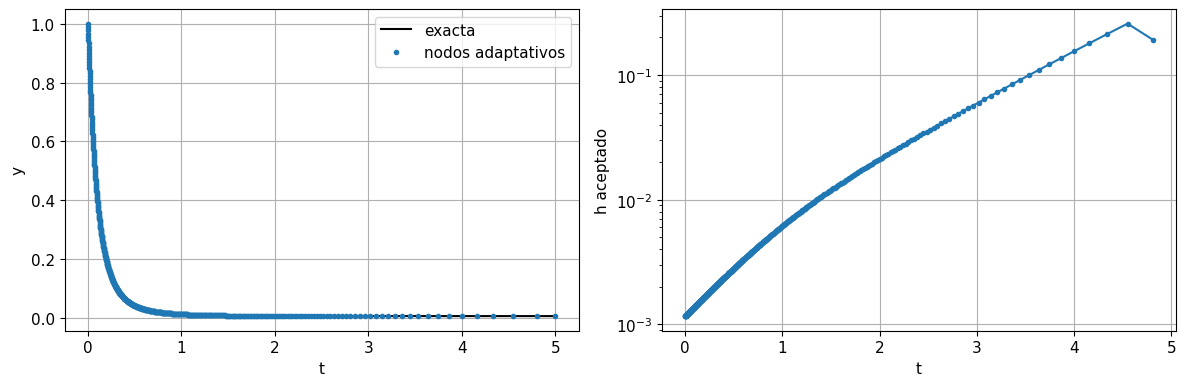

In [3]:
fun=lambda t,y:-10*np.exp(-2*t)*y
exact=lambda t:np.exp(-5*(1-np.exp(-2*t)))
t,y,rejected,nfev=adaptive_heun(fun,(0,5),1.,rtol=1e-4,atol=1e-7)
fig,ax=plt.subplots(1,2,figsize=(12,4))
q=np.linspace(0,5,500); ax[0].plot(q,exact(q),"k",label="exacta")
ax[0].plot(t,y[:,0],".",label="nodos adaptativos"); ax[0].legend()
ax[0].set(xlabel="t",ylabel="y")
ax[1].semilogy(t[:-1],np.diff(t),".-"); ax[1].set(xlabel="t",ylabel="h aceptado")
plt.tight_layout(); plt.show()
print("Rechazos:",rejected,"Evaluaciones:",nfev)

**Interpretación.** Los pasos deberían ser pequeños durante el transitorio y crecer luego. El último paso puede ser más corto porque se recorta para llegar a $T$; esa reducción no necesariamente indica un aumento de dificultad.

## 5. Barrido de tolerancias

Estrechamos tolerancias y medimos el error máximo en los nodos aceptados. Ese error global no tiene obligación de ser exactamente igual a `rtol`. Además el conjunto de nodos cambia entre ejecuciones, por lo que una comparación estricta de normas de trayectoria podría requerir una malla común.

Para este par educativo, el estimador es conservador respecto a la solución de Heun y puede producir errores mucho menores que la tolerancia nominal. No extrapoles esa proporción a cualquier par o ecuación.

rtol=1e-02, error=8.363e-04, nfev=120, rechazos=1
rtol=1e-03, error=8.038e-05, nfev=356, rechazos=2
rtol=1e-04, error=7.966e-06, nfev=1094, rechazos=3
rtol=1e-05, error=7.951e-07, nfev=3420, rechazos=3


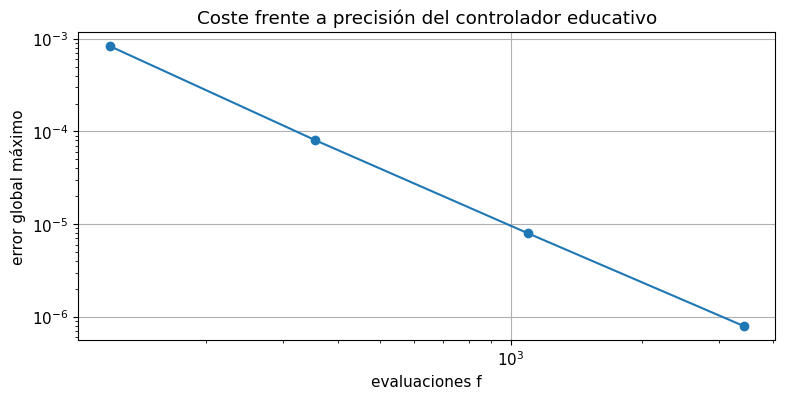

In [4]:
tols=np.array([1e-2,1e-3,1e-4,1e-5]); errors=[]; costs=[]
for tol in tols:
    tt,yy,rej,cost=adaptive_heun(fun,(0,5),1.,rtol=tol,atol=tol*1e-3)
    errors.append(np.max(abs(yy[:,0]-exact(tt)))); costs.append(cost)
    print(f"rtol={tol:.0e}, error={errors[-1]:.3e}, nfev={cost}, rechazos={rej}")
plt.loglog(costs,errors,"o-"); plt.xlabel("evaluaciones f"); plt.ylabel("error global máximo")
plt.title("Coste frente a precisión del controlador educativo"); plt.show()

**Interpretación.** Más precisión requiere más evaluaciones, pero la relación depende del problema y del estimador. Una comparación con paso fijo debe pedir un error global parecido para evaluar eficiencia.

## 6. RK45 de SciPy y sus pasos internos

`solve_ivp` devuelve sus nodos internos si no se proporciona `t_eval`. Puede construirse una representación interpolada usando `dense_output=True`. Al pasar `t_eval`, los tiempos devueltos son los solicitados, de modo que no permiten deducir directamente los pasos del solver.

La salida densa es una aproximación interpolada específica del método, no una integración nueva en cada tiempo. Sirve para evaluar observaciones y eventos, pero también tiene error.

Éxito: True nfev: 290 nodos: 48


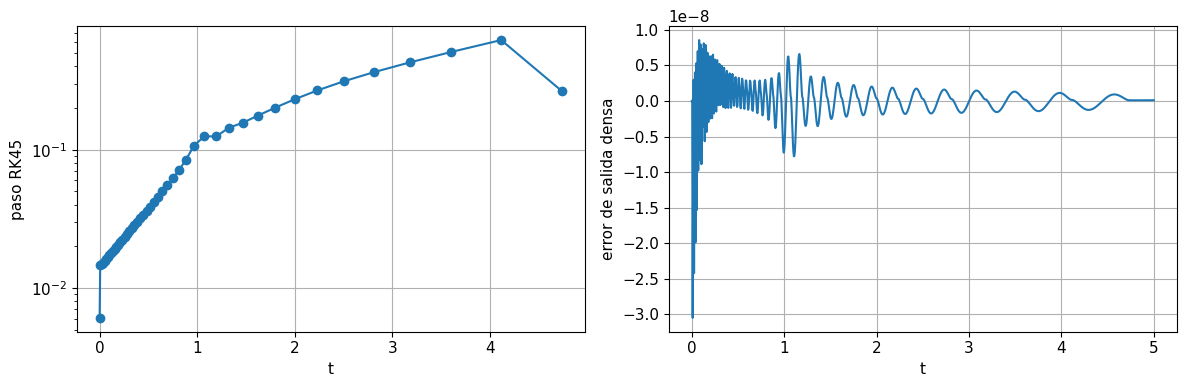

In [5]:
sol=solve_ivp(fun,(0,5),[1.],method="RK45",rtol=1e-7,atol=1e-10,dense_output=True)
q=np.linspace(0,5,1001)
fig,ax=plt.subplots(1,2,figsize=(12,4))
ax[0].semilogy(sol.t[:-1],np.diff(sol.t),"o-"); ax[0].set(xlabel="t",ylabel="paso RK45")
ax[1].plot(q,sol.sol(q)[0]-exact(q)); ax[1].set(xlabel="t",ylabel="error de salida densa")
plt.tight_layout(); plt.show()
print("Éxito:",sol.success,"nfev:",sol.nfev,"nodos:",len(sol.t))

**Interpretación.** RK45 requiere menos pasos que el par sencillo para gran precisión por su mayor orden y estimador más sofisticado. La diferencia ilustra por qué se usa una biblioteca madura en producción, manteniendo la implementación simple para comprender los mecanismos.

## 7. Detectar eventos científicos

Un evento es una función $g(t,y)$ cuya raíz interesa: una altura cero, un umbral de temperatura o una población dada. Para $y'= -y$, detectaremos $y=0.2$, cuyo tiempo exacto es $\log5$.

`direction=-1` selecciona cruces descendentes y `terminal=True` detiene la integración. Los eventos se detectan a partir de cambios de signo durante pasos; varios cruces dentro de un paso pueden pasar inadvertidos. Si la escala del evento lo exige, limita `max_step`.

Tiempo detectado: 1.6094379126771825 Exacto: 1.6094379124341003


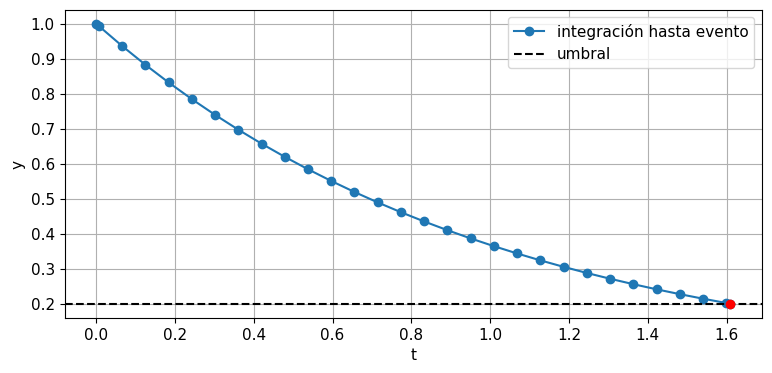

In [6]:
def event(t,y): return y[0]-0.2
event.direction=-1; event.terminal=True
out=solve_ivp(lambda t,y:-y,(0,5),[1.],events=event,rtol=1e-9,atol=1e-12)
print("Tiempo detectado:",out.t_events[0][0],"Exacto:",np.log(5))
plt.plot(out.t,out.y[0],"o-",label="integración hasta evento")
plt.axhline(0.2,color="k",linestyle="--",label="umbral")
plt.scatter(out.t_events[0],out.y_events[0][:,0],color="red",zorder=5)
plt.xlabel("t"); plt.ylabel("y"); plt.legend(); plt.show()

**Interpretación.** El evento se localiza entre pasos mediante la representación interna de la solución. Su precisión depende de la integración y de la localización de la raíz, no solo de la cantidad de puntos mostrados.

## 8. Adaptación no equivale a resolver rigidez

Un controlador reduce $h$ cuando el estimador crece, pero un método explícito sigue limitado por estabilidad. En un problema rígido puede gastar muchos pasos en un modo rápido ya casi invisible. Si las evaluaciones son excesivas, compara con `Radau` o `BDF` y estudia las escalas del jacobiano.

Rechazos persistentes también pueden indicar discontinuidades, un error en $f$ o tolerancias incompatibles con la precisión de la evaluación. El número de pasos por sí solo no identifica la causa. Controlar error y escoger una familia estable son decisiones complementarias.

## 9. Tolerancias, diferenciación y reproducibilidad

En una Neural ODE, cambios pequeños de parámetros pueden cambiar la secuencia de pasos aceptados. El solver adaptativo es parte de la evaluación de la pérdida. Describe método, tolerancias y eventos al reproducir resultados; cambiar esas opciones puede modificar tanto coste como gradientes.

Para estados de distinto tamaño, utiliza un vector de tolerancias absolutas. Evita pedir una tolerancia menor que el nivel de ruido del simulador. Si necesitas comparar trayectorias, evalúa todas en tiempos comunes y mantén el mismo operador de observación. Para sistemas caóticos, un error puntual tardío enorme no implica automáticamente que estadísticas de largo plazo sean inútiles, pero ambas cuestiones requieren criterios distintos.

## 10. Convergencia, error y coste: cómo hacer una comparación justa

El orden depende del par utilizado; Heun tiene orden global $p=2$. Si un método tiene orden global $p$, en el régimen asintótico se espera $E(h)\approx C h^p$ para problemas suficientemente suaves y un intervalo temporal fijo. El estimador
$$p_{\rm obs}=\log_2\frac{E(h)}{E(h/2)}$$
solo es significativo mientras el error de referencia y el redondeo sean menores que el error medido. Una trayectoria visualmente correcta puede tener error de fase, sesgo en un observable o errores localizados en transitorios.

Para comparar métodos, cuenta evaluaciones de $f$, resoluciones lineales y, en métodos implícitos, iteraciones de Newton. Un método de más orden puede ser más barato para una precisión dada, pero no necesariamente para una tolerancia muy laxa o una función no suave. Si aparecen discontinuidades o eventos, separa los intervalos suaves y localiza el cambio.

Guarda el tiempo final real de cada integración. Usar `int(T/h)` puede terminar antes de $T$ si el cociente no es entero. En estos ejemplos fijamos el número de pasos y calculamos $h=(T-t_0)/N$ para llegar exactamente al extremo. Una malla de salida fija tampoco debe confundirse con los pasos internos de un solver adaptativo.

## 11. De la simulación a SciML

En un problema inverso se ajusta un parámetro $\theta$ minimizando
$$L_h(\theta)=\sum_i\left[y_h(t_i;\theta)-y_i^{\rm obs}\right]^2.$$
El subíndice $h$ recuerda que estamos optimizando la salida de un simulador discretizado. Si el método adaptativo genera un sesgo sistemático, el ajuste puede compensarlo con un parámetro equivocado. Repite la inferencia con una malla más fina y observa si el parámetro estimado cambia.

En una Neural ODE, $f_\theta(t,y)$ puede ser una red, pero el solver conserva sus requisitos de regularidad y estabilidad. Reducir la pérdida de entrenamiento no prueba precisión de integración. Para física diferenciable, una derivada del programa discreto es una sensibilidad de ese programa; hace falta verificar que se estabiliza al refinar la discretización.

Define qué observable importa: valor final, energía, evento, amplitud o una norma de trayectoria. No compares únicamente la apariencia de curvas. Una evaluación científica útil separa error de datos, error de modelo y error numérico, porque mejorar uno de ellos no garantiza mejorar los demás.

| Inicio | Anterior | Siguiente |
| --- | --- | --- |
| [🏠](../README.md) | [⏪](../7_METODOS_NUMERICOS_PARA_ODE/7_4_Runge_Kutta.ipynb) | [⏩](../7_METODOS_NUMERICOS_PARA_ODE/7_6_Metodos_implicitos.ipynb) |